# v1 – Sentimento com ML clássico

Classificação das avaliações da Olist em positivas/negativas com TF-IDF + regressão logística.

## Passo 1 – Carregar e explorar

Antes de treinar qualquer modelo, conhecer os dados: tamanho, colunas, como as notas se distribuem e quantas avaliações têm texto (só essas servem para um classificador de sentimento).

### 1. Imports e constantes

Caminho e nomes de colunas vêm de `delivery_ai.config`, e a limpeza vem de `delivery_ai.data` (código testado em `src/`). Assim notebook, testes e treino usam exatamente os mesmos valores.

In [1]:
import time
from dataclasses import asdict

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from delivery_ai.config import (
    ID_COLUMN,
    MESSAGE_COLUMN,
    NEGATIVE,
    RANDOM_STATE,
    SCORE_COLUMN,
    SENTIMENT_COLUMN,
    SENTIMENT_NAMES,
)
from delivery_ai.data import (
    drop_duplicate_reviews,
    drop_neutral_reviews,
    keep_reviews_with_text,
    load_reviews,
    prepare_sentiment_dataset,
    split_train_test,
)
from delivery_ai.evaluation import evaluate_predictions
from delivery_ai.models import (
    CLASSIFIER_STEP,
    VECTORIZER_STEP,
    build_baseline_model,
    build_sentiment_model,
    build_tfidf_vectorizer,
)

BAR_COLOR = "#2a78d6"

### 2. Carregar e ver o tamanho

In [2]:
reviews = load_reviews()

print(f"{reviews.shape[0]:,} linhas x {reviews.shape[1]} colunas")
reviews.head()

99,224 linhas x 7 colunas


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


### 3. Colunas e valores faltantes

O percentual de faltantes mostra quais informações dá para usar de verdade.

In [3]:
missing_percent = reviews.isna().mean().mul(100).round(1)

pd.DataFrame({"tipo": reviews.dtypes, "% faltante": missing_percent})

,tipo,% faltante
review_id,str,0.0
order_id,str,0.0
review_score,int64,0.0
review_comment_title,str,88.3
review_comment_message,str,58.7
review_creation_date,str,0.0
review_answer_timestamp,str,0.0


In [4]:
duplicated_ids = reviews[ID_COLUMN].duplicated().sum()

print(f"{ID_COLUMN} repetidos: {duplicated_ids}")

review_id repetidos: 814


### 4. Distribuição das notas

Mostra se as classes estão equilibradas. Se uma nota domina, um modelo que "chuta" sempre ela já acerta muito, e a acurácia sozinha engana.

In [5]:
def score_distribution(scores: pd.Series) -> pd.DataFrame:
    """Contagem e percentual de cada nota, de 1 a 5, para comparar grupos lado a lado."""
    counts = scores.value_counts().sort_index()
    return pd.DataFrame({"avaliações": counts, "%": (counts / counts.sum() * 100).round(1)})


all_scores = score_distribution(reviews[SCORE_COLUMN])
all_scores

,avaliações,%
review_score,,
1,11424,11.5
2,3151,3.2
3,8179,8.2
4,19142,19.3
5,57328,57.8


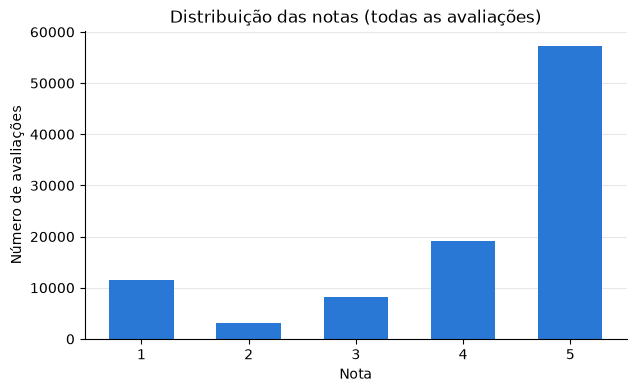

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(all_scores.index, all_scores["avaliações"], width=0.6, color=BAR_COLOR)
ax.set_title("Distribuição das notas (todas as avaliações)")
ax.set_xlabel("Nota")
ax.set_ylabel("Número de avaliações")
ax.set_xticks(all_scores.index)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### 5. Quantas avaliações têm texto

Conta como comentário só a mensagem que não é vazia e não tem apenas espaços (regra de `keep_reviews_with_text`).

In [7]:
with_comment = keep_reviews_with_text(reviews)
comment_share = len(with_comment) / len(reviews)

print(f"Com comentário: {len(with_comment):,} ({comment_share:.1%})")
print(f"Sem comentário: {len(reviews) - len(with_comment):,} ({1 - comment_share:.1%})")

Com comentário: 40,950 (41.3%)
Sem comentário: 58,274 (58.7%)


### 6. Notas entre quem comentou

O modelo só vai ver avaliações com texto. Se clientes insatisfeitos comentam mais, o equilíbrio entre as notas muda em relação ao total.

In [8]:
pd.DataFrame(
    {
        "% todas": all_scores["%"],
        "% com comentário": score_distribution(with_comment[SCORE_COLUMN])["%"],
    }
)

,% todas,% com comentário
review_score,,
1,11.5,21.4
2,3.2,5.2
3,8.2,8.7
4,19.3,14.6
5,57.8,50.1


### 7. Conclusões

| O que vimos | Número | O que significa para a modelagem |
|---|---|---|
| Tamanho | 99.224 avaliações, 7 colunas | Volume suficiente para ML clássico. |
| Com comentário | 40.950 (41,3%) | ~59% das linhas não têm texto e saem do treino. O título (88% vazio) não compensa. |
| Nota 5 | 57,8% do total | Classes desbalanceadas: um modelo que sempre diz "positivo" já acerta muito. Por isso o baseline com `DummyClassifier` e métricas além da acurácia (F1, recall da classe negativa). |
| Notas 1–2 entre quem comentou | 26,6% (contra 14,7% no total) | Quem está insatisfeito comenta mais, então o conjunto com texto é menos desbalanceado que o total. |
| `review_id` repetidos | 814 | Precisam ser tratados na preparação para não contar a mesma avaliação duas vezes. |

**Próximo passo:** definir o rótulo (positivo/negativo) a partir da nota e decidir o que fazer com a nota 3.


## Passo 2 – Limpar e rotular

A limpeza fica em `src/delivery_ai/data.py`, coberta por testes; aqui ela só é aplicada e conferida.

Regras: manter só avaliações com texto, remover `review_id` repetido, descartar a nota 3 e rotular notas 1–2 como **negativo (0)** e 4–5 como **positivo (1)**.

### 1. Funil da limpeza

Quantas avaliações sobram a cada etapa: mostra onde perdemos dados e por quê.

In [9]:
without_duplicates = drop_duplicate_reviews(with_comment)
without_neutral = drop_neutral_reviews(without_duplicates)

funnel = pd.Series(
    {
        "Total": len(reviews),
        "Com texto": len(with_comment),
        "Sem duplicatas": len(without_duplicates),
        "Sem nota 3": len(without_neutral),
    },
    name="avaliações",
)
funnel.to_frame().assign(**{"% do total": (funnel / len(reviews) * 100).round(1)})

,avaliações,% do total
Total,99224,100.0
Com texto,40950,41.3
Sem duplicatas,40641,41.0
Sem nota 3,37113,37.4


### 2. Conjunto final e distribuição do sentimento

`prepare_sentiment_dataset` faz todas as etapas de uma vez; o `assert` confere que o resultado bate com o funil.

In [10]:
sentiment_dataset = prepare_sentiment_dataset(reviews)
assert len(sentiment_dataset) == funnel["Sem nota 3"]

sentiment_counts = sentiment_dataset[SENTIMENT_COLUMN].map(SENTIMENT_NAMES).value_counts()
pd.DataFrame(
    {
        "avaliações": sentiment_counts,
        "%": (sentiment_counts / sentiment_counts.sum() * 100).round(1),
    }
)

,avaliações,%
sentiment,,
positivo,26355,71.0
negativo,10758,29.0


### 3. Exemplos de cada classe

Ler alguns textos confere se o rótulo vindo da nota faz sentido.

In [11]:
EXAMPLES_PER_CLASS = 5

for label, name in SENTIMENT_NAMES.items():
    print(f"--- {name} ---")
    examples = sentiment_dataset[sentiment_dataset[SENTIMENT_COLUMN] == label].sample(
        EXAMPLES_PER_CLASS, random_state=RANDOM_STATE
    )
    for score, message in zip(examples[SCORE_COLUMN], examples[MESSAGE_COLUMN], strict=True):
        print(f"[nota {score}] {message}")
    print()

--- negativo ---
[nota 1] eu pedi o cancelamento na mesma hora e mesmo a assim mandaram para o correio só quero estorno o brigador 
[nota 1] Meu produto não foi entregue!! Quero meu dinheiro de volta!
[nota 1] Recebi a mercadoria e o produto não é ata funcionando!!! 
[nota 1] Não fiquei satisfeita; propaganda enganosa pois, disseram que era luminoso e na verdade NÃO É.E agora? Eu preciso que seja luminoso à noite lógico para aplicação de remédios tipo insulina,Vainia Lúcia
[nota 1] O produro não chegou. Não me deram nenbuma satisfação

--- positivo ---
[nota 5] O relógio é lindo e a entrega foi muito rápida, ele foi postado dia 24 e chegou dia 30, sendo que era frete comum e para o nordeste. Comprarei mais vezes!
[nota 5] Produto entregue antes do prazo. Muito bom.
[nota 5] recebi o produto intacto
[nota 5] O esperado. Obrigado!
[nota 5] Boneca original em perfeito estado.



### 4. Conclusões

- **37.113 avaliações** prontas para o modelo (37,4% do total): 26.355 positivas (71,0%) e 10.758 negativas (29,0%).
- O texto é o grande filtro: ~59% das avaliações não têm comentário. As duplicatas (309 linhas) e a nota 3 (3.528) pesam pouco.
- Continua desbalanceado (cerca de 7 positivas para cada 3 negativas). Um modelo que sempre diz "positivo" acertaria 71%, e esse é o número que o modelo de verdade precisa superar com folga.

**Por que descartar a nota 3?** Ela é ambígua: "chegou, mas atrasou" pode ser elogio ou reclamação. Forçá-la para um dos lados colocaria rótulos contraditórios no treino (ruído), e o modelo aprenderia uma fronteira confusa. Sem ela, o problema binário fica claro. A limitação é que, em produção, textos "mornos" ainda vão chegar, e o modelo vai empurrá-los para um dos lados.

**Próximo passo:** separar treino e teste e criar o baseline com `DummyClassifier`.


## Passo 3 – Separar treino e teste

O modelo aprende com o **treino (80%)** e é avaliado no **teste (20%)**, que ele nunca viu. `split_train_test` (em `src/`) usa `stratify` para manter a mesma proporção de positivas e negativas nas duas partes.

In [12]:
split = split_train_test(sentiment_dataset)

print(f"Treino: {len(split.train):,} avaliações")
print(f"Teste:  {len(split.test):,} avaliações")

Treino: 29,690 avaliações
Teste:  7,423 avaliações


### 1. Proporção de sentimento em cada parte

In [13]:
def sentiment_share(dataset: pd.DataFrame) -> pd.Series:
    """Percentual de cada sentimento, para comparar as partes lado a lado."""
    names = dataset[SENTIMENT_COLUMN].map(SENTIMENT_NAMES)
    return names.value_counts(normalize=True).mul(100).round(2)


pd.DataFrame(
    {
        "% total": sentiment_share(sentiment_dataset),
        "% treino": sentiment_share(split.train),
        "% teste": sentiment_share(split.test),
    }
)

,% total,% treino,% teste
sentiment,,,
positivo,71.01,71.01,71.01
negativo,28.99,28.99,28.99


### 2. Textos repetidos entre treino e teste

Avaliações diferentes podem ter exatamente o mesmo texto ("Muito bom"). Não é vazamento: são clientes diferentes, e em produção essas frases também chegam. Mas acertar esses casos é mais fácil, então o número fica registrado para a análise de erros.

In [14]:
def normalize_message(messages: pd.Series) -> pd.Series:
    """Ignora maiúsculas e espaços nas pontas, para comparar só o conteúdo."""
    return messages.str.strip().str.lower()


train_messages = set(normalize_message(split.train[MESSAGE_COLUMN]))
repeated_in_test = normalize_message(split.test[MESSAGE_COLUMN]).isin(train_messages)

print(
    f"Teste com texto idêntico a algum do treino: "
    f"{repeated_in_test.sum():,} ({repeated_in_test.mean():.1%})"
)
normalize_message(split.test.loc[repeated_in_test, MESSAGE_COLUMN]).value_counts().head(10)

Teste com texto idêntico a algum do treino: 1,181 (15.9%)


review_comment_message
muito bom                79
bom                      67
recomendo                41
otimo                    39
excelente                35
ótimo                    32
ok                       31
tudo ok                  22
boa                      17
chegou antes do prazo    16
Name: count, dtype: int64

### 3. Conclusões

- **29.690 avaliações de treino e 7.423 de teste** (80/20).
- A proporção é **idêntica nas duas partes: 71,01% positivas e 28,99% negativas**. Sem `stratify`, o teste poderia ficar com mais ou menos negativas por acaso, e a métrica mudaria por sorte, não por mérito do modelo.
- **15,9% do teste** (1.181 avaliações) repete um texto que também aparece no treino, quase sempre frases curtas como "muito bom" e "recomendo". Na análise de erros vale medir o desempenho também só nos textos inéditos.
- Detalhe que já aparece aqui: "otimo" e "ótimo" contam como textos diferentes. A remoção de acentos é uma opção a considerar na vetorização com TF-IDF.

O teste fica guardado para a avaliação final. Escolhas e ajustes do modelo usam apenas o treino.

**Próximo passo:** criar o baseline com `DummyClassifier` e medir o que um modelo "sem inteligência" já consegue.


## Passo 4 – Baseline "burro"

Antes do modelo de verdade, um modelo que **não lê o texto**: o `DummyClassifier` prevê sempre a classe mais comum do treino (positivo). Ele define o piso: qualquer modelo útil precisa superá-lo com folga.

In [15]:
baseline = build_baseline_model().fit(split.train[MESSAGE_COLUMN], split.train[SENTIMENT_COLUMN])
baseline_predictions = pd.Series(
    baseline.predict(split.test[MESSAGE_COLUMN]), index=split.test.index
)

baseline_predictions.map(SENTIMENT_NAMES).value_counts()

positivo    7423
Name: count, dtype: int64

### 1. Métricas no teste

- **Acurácia**: % de acertos no geral.
- **Precisão (negativo)**: das avaliações que o modelo chamou de negativas, quantas eram mesmo negativas.
- **Recall (negativo)**: das avaliações negativas de verdade, quantas o modelo encontrou.
- **F1 (negativo)**: equilíbrio entre precisão e recall; só é alto se os dois forem altos.
- **F1 macro**: média do F1 das duas classes, com o mesmo peso para cada uma.

In [16]:
baseline_metrics = evaluate_predictions(split.test[SENTIMENT_COLUMN], baseline_predictions)

pd.Series(asdict(baseline_metrics), name="baseline").round(3).to_frame()

,baseline
accuracy,0.710
negative_precision,0.000
negative_recall,0.000
negative_f1,0.000
macro_f1,0.415


### 2. Matriz de confusão

Linhas: o sentimento real. Colunas: o que o modelo previu. A diagonal são os acertos.

In [17]:
sentiment_order = list(SENTIMENT_NAMES.values())

pd.crosstab(
    split.test[SENTIMENT_COLUMN].map(SENTIMENT_NAMES).rename("real"),
    baseline_predictions.map(SENTIMENT_NAMES).rename("previsto"),
).reindex(index=sentiment_order, columns=sentiment_order, fill_value=0)

previsto,negativo,positivo
real,,
negativo,0,2152
positivo,0,5271


### 3. Conclusões

- O baseline previu **positivo para todas as 7.423 avaliações** do teste.
- **Acurácia de 71,0%** parece boa, mas é só a proporção de positivas no teste: o modelo não aprendeu nada.
- **Recall e F1 negativos = 0**: das 2.152 avaliações negativas, nenhuma foi encontrada. Como "detector de cliente insatisfeito", ele é inútil.
- **F1 macro = 0,415**: ao dar o mesmo peso às duas classes, a métrica expõe o problema que a acurácia esconde.

**Por que a acurácia sozinha engana:** com classes desbalanceadas, acertar sempre a classe majoritária já dá uma acurácia alta. Por isso a v1 vai ser julgada principalmente pelo **F1 da classe negativa** e pelo **F1 macro**, sempre comparados com este piso.

**Próximo passo:** treinar o modelo de verdade (TF-IDF + regressão logística) e comparar com o baseline.


## Passo 5 – Texto em números (TF-IDF)

Modelos só entendem números. O TF-IDF transforma cada avaliação numa linha de uma tabela: **uma coluna por palavra do vocabulário**, com um peso que é alto quando a palavra é frequente *nesta* avaliação e rara *nas outras*.

O vocabulário e os pesos são aprendidos **só no treino** (`fit_transform`). O teste é apenas convertido (`transform`) com o que foi aprendido, como acontecerá com avaliações novas em produção.

In [18]:
vectorizer = build_tfidf_vectorizer()
train_matrix = vectorizer.fit_transform(split.train[MESSAGE_COLUMN])
test_matrix = vectorizer.transform(split.test[MESSAGE_COLUMN])

print(f"Treino: {train_matrix.shape[0]:,} linhas x {train_matrix.shape[1]:,} colunas")
print(f"Teste:  {test_matrix.shape[0]:,} linhas x {test_matrix.shape[1]:,} colunas")

Treino: 29,690 linhas x 5,671 colunas
Teste:  7,423 linhas x 5,671 colunas


### 1. Uma matriz quase toda zerada

Cada avaliação usa poucas palavras do vocabulário inteiro, então quase todas as células são zero. Por isso o scikit-learn guarda a matriz em formato **esparso**: só os valores diferentes de zero e suas posições.

In [19]:
total_cells = train_matrix.shape[0] * train_matrix.shape[1]
filled_share = train_matrix.nnz / total_cells
sparse_bytes = train_matrix.data.nbytes + train_matrix.indices.nbytes + train_matrix.indptr.nbytes
dense_bytes = total_cells * train_matrix.dtype.itemsize

print(f"Células preenchidas: {train_matrix.nnz:,} de {total_cells:,} ({filled_share:.3%})")
print(f"Média de palavras por avaliação: {train_matrix.nnz / train_matrix.shape[0]:.1f}")
print(f"Memória: {sparse_bytes / 1e6:.1f} MB esparsa x {dense_bytes / 1e6:,.0f} MB se fosse densa")

Células preenchidas: 277,717 de 168,371,990 (0.165%)
Média de palavras por avaliação: 9.4
Memória: 3.5 MB esparsa x 1,347 MB se fosse densa


### 2. O TF-IDF por dentro

O **IDF** mede o quanto uma palavra é rara no treino. Palavras que aparecem em muitas avaliações ("produto", "entrega") têm IDF baixo e pesam pouco; palavras específicas pesam mais.

In [20]:
vocabulary = vectorizer.get_feature_names_out()
idf = pd.Series(vectorizer.idf_, index=vocabulary, name="IDF").sort_values()

idf.head(10)

produto    1.878809
do         2.383570
nao        2.513213
de         2.530025
prazo      2.558583
muito      2.697249
entrega    2.843281
que        2.877477
antes      2.925970
chegou     3.008558
Name: IDF, dtype: float64

Os pesos de uma avaliação do treino (a primeira com pelo menos algumas palavras no vocabulário):

In [21]:
MIN_EXAMPLE_TERMS = 6

example_position = int((train_matrix.getnnz(axis=1) >= MIN_EXAMPLE_TERMS).argmax())
example_row = train_matrix[example_position]

print(split.train[MESSAGE_COLUMN].iloc[example_position])
pd.Series(example_row.data, index=vocabulary[example_row.indices], name="peso TF-IDF").sort_values(
    ascending=False
)

AINDA NÃO RECEBI MEU PRODUTO, O PRAZO DE ENTREGA JÁ PASSOU DESDO DIA 20/02/2018


desdo      0.503310
2018       0.345785
passou     0.338862
20         0.337390
02         0.328133
dia        0.235959
ja         0.216566
meu        0.206892
ainda      0.200928
recebi     0.159427
entrega    0.144371
prazo      0.129915
de         0.128465
nao        0.127612
produto    0.095399
Name: peso TF-IDF, dtype: float64

### 3. Palavras que o vocabulário não conhece

Como o vocabulário veio só do treino, palavras que aparecem apenas no teste são ignoradas. É o vazamento de dados sendo evitado: o teste simula o mundo real, onde chegam palavras que o modelo nunca viu.

In [22]:
analyzer = vectorizer.build_analyzer()
test_words = split.test[MESSAGE_COLUMN].map(analyzer).explode().dropna()
unknown_words = test_words[~test_words.isin(set(vocabulary))]
reviews_without_known_words = int((test_matrix.getnnz(axis=1) == 0).sum())

print(f"Palavras distintas do teste fora do vocabulário: {unknown_words.nunique():,}")
print(f"Avaliações do teste sem nenhuma palavra conhecida: {reviews_without_known_words:,}")
unknown_words.value_counts().head(10)

Palavras distintas do teste fora do vocabulário: 2,262
Avaliações do teste sem nenhuma palavra conhecida: 49


review_comment_message
acerca          5
s8              5
hidratacao      4
xerox           4
shoptaime       4
galaxy          4
bases           4
encomendados    4
esponja         4
respeita        4
Name: count, dtype: int64

### 4. Conclusões

- **Treino: 29.690 × 5.671. Teste: 7.423 × 5.671.** As duas matrizes têm as mesmas colunas, porque o vocabulário é um só, aprendido no treino.
- **Só 0,165% das células são diferentes de zero**: cada avaliação usa, em média, 9,4 palavras de um vocabulário de 5.671. No formato esparso, a matriz ocupa 3,5 MB, contra 1,3 GB se fosse guardada inteira.
- O IDF faz o que promete: "produto", "prazo" e "entrega" aparecem em todo lugar e pesam pouco.
- **Limitação:** o TF-IDF mede raridade, não sentimento. No exemplo, "desdo" (erro de digitação) e os números da data receberam os maiores pesos. Quem aprende quais palavras importam para o sentimento é o classificador do próximo passo.
- **2.262 palavras do teste ficaram fora do vocabulário**, e 49 avaliações do teste não têm nenhuma palavra conhecida (para o modelo, viram uma linha toda zerada). É o preço de não vazar informação, e é exatamente o que vai acontecer em produção.

**Por que o vocabulário é aprendido só no treino:** o `fit` decide quais palavras viram colunas e calcula o IDF com as frequências dos textos que vê. Se o teste entrasse no `fit`, informação da "prova" contaminaria o aprendizado (vazamento de dados) e a métrica sairia otimista demais.

**Próximo passo:** treinar a regressão logística sobre essa matriz e comparar com o baseline.


## Passo 6 – Treinar a regressão logística

O primeiro modelo que de fato lê o texto. A **regressão logística** dá um peso a cada palavra do vocabulário: pesos negativos puxam para "negativo", positivos puxam para "positivo". Para classificar uma avaliação, ela soma os pesos das palavras presentes (multiplicados pelo TF-IDF) e transforma o total numa probabilidade.

`build_sentiment_model` junta o TF-IDF do Passo 5 e a regressão num **pipeline**: um único `fit` aprende o vocabulário e os pesos só com o treino. O teste continua guardado para o próximo passo.

In [23]:
sentiment_model = build_sentiment_model()

start = time.perf_counter()
sentiment_model.fit(split.train[MESSAGE_COLUMN], split.train[SENTIMENT_COLUMN])
training_seconds = time.perf_counter() - start

model_vocabulary = sentiment_model.named_steps[VECTORIZER_STEP].get_feature_names_out()
classifier = sentiment_model.named_steps[CLASSIFIER_STEP]

print(f"Treino em {training_seconds:.2f} s ({classifier.n_iter_[0]} iterações)")
print(f"Vocabulário: {len(model_vocabulary):,} palavras (no Passo 5: {len(vocabulary):,})")

Treino em 0.27 s (20 iterações)
Vocabulário: 5,671 palavras (no Passo 5: 5,671)


### 1. O que o modelo aprendeu

As palavras com maior peso para cada lado. Como as classes são 0 = negativo e 1 = positivo, um peso negativo empurra a previsão para "negativo".

In [24]:
TOP_WORDS = 15

word_weights = pd.Series(classifier.coef_[0], index=model_vocabulary).sort_values()
most_negative = word_weights.head(TOP_WORDS)
most_positive = word_weights.tail(TOP_WORDS).sort_values(ascending=False)

pd.concat(
    {
        "mais negativas": most_negative.round(2).rename_axis("palavra").reset_index(name="peso"),
        "mais positivas": most_positive.round(2).rename_axis("palavra").reset_index(name="peso"),
    },
    axis=1,
)

mais negativas        mais positivas      
          palavra   peso        palavra  peso
0             nao -10.19          antes  5.78
1         pessima  -5.20      excelente  5.15
2         pessimo  -3.89         rapida  5.07
3         comprei  -3.85          otimo  4.82
4       diferente  -3.81       parabens  4.78
5             nem  -3.78      recomendo  4.38
6            ruim  -3.73         testei  4.00
7           baixa  -3.63          lindo  3.99
8      aguardando  -3.59         rapido  3.93
9        quebrado  -3.38          otima  3.89
10       inferior  -3.36           amei  3.78
11         demora  -3.29           tudo  3.75
12       faltando  -3.19            bem  3.60
13         passou  -2.85     satisfeito  3.58
14          quero  -2.82         adorei  3.58

### 2. De volta ao exemplo do Passo 5

No TF-IDF, "desdo" (erro de digitação) e os números da data tinham os maiores pesos, porque são raros. Para o modelo, o que pesa é outra coisa:

In [25]:
example_words = vocabulary[example_row.indices]

pd.DataFrame(
    {
        "peso TF-IDF (raridade)": example_row.data,
        "peso no modelo (sentimento)": word_weights.reindex(example_words).to_numpy(),
    },
    index=example_words,
).round(2).sort_values("peso no modelo (sentimento)")

,peso TF-IDF (raridade),peso no modelo (sentimento)
nao,0.13,-10.19
passou,0.34,-2.85
meu,0.21,-2.02
ja,0.22,-1.76
recebi,0.16,-1.54
de,0.13,-1.54
02,0.33,-1.21
2018,0.35,-0.80
produto,0.10,-0.69
20,0.34,-0.68


### 3. Teste de sanidade com frases inventadas

Ainda não é a avaliação (ela vem no próximo passo, com o teste): só confere se o modelo se comporta como esperado.

In [26]:
sample_reviews = [
    "não recebi o produto",
    "chegou antes do prazo, adorei",
    "produto veio quebrado",
    "tudo certo, recomendo",
    "entregaram o produto errado",
]
negative_column = list(classifier.classes_).index(NEGATIVE)

pd.DataFrame(
    {
        "previsão": pd.Series(sentiment_model.predict(sample_reviews))
        .map(SENTIMENT_NAMES)
        .to_numpy(),
        "prob. negativo": sentiment_model.predict_proba(sample_reviews)[:, negative_column].round(
            2
        ),
    },
    index=sample_reviews,
)

,previsão,prob. negativo
não recebi o produto,negativo,1.00
"chegou antes do prazo, adorei",positivo,0.00
produto veio quebrado,negativo,0.95
"tudo certo, recomendo",positivo,0.00
entregaram o produto errado,negativo,0.87


### 4. Conclusões

- **Treina em menos de 1 segundo** (20 iterações) com 29.690 avaliações e 5.671 palavras, sem nenhum aviso de convergência.
- Os pesos fazem sentido: "nao" (−10,2), "pessima", "ruim", "quebrado", "aguardando" puxam para negativo; "excelente", "rapida", "otimo", "recomendo", "antes" puxam para positivo.
- **Correlação não é causa:** "comprei" e "2018" têm peso negativo porque as reclamações costumam contar a história ("comprei dia X e não chegou"), não porque a palavra em si seja ruim.
- **O modelo corrige a limitação do TF-IDF:** "desdo", que tinha o maior peso TF-IDF, quase não pesa no sentimento (−0,17).
- **Nova limitação, a da "sacola de palavras":** o modelo não vê a ordem das palavras. "prazo" é positivo (+3,47) por causa de "antes do prazo", mas puxa para o lado errado em "o prazo já passou". Da mesma forma, "nao" tem um peso tão forte que frases como "não tive problema" podem virar negativas. Pares de palavras (bigramas) são um caminho para isso, a ser testado por métrica.
- As frases inventadas foram classificadas corretamente, inclusive "entregaram o produto errado" (87% negativo), que não tem nenhuma palavra "ruim" explícita.

**Próximo passo:** avaliar no teste e comparar com o baseline.


## Passo 7 – Avaliar

Agora, pela primeira vez, o modelo encara o **teste**: 7.423 avaliações que ele nunca viu. As métricas são as mesmas do baseline (Passo 4), para a comparação ser justa.

In [27]:
model_predictions = pd.Series(
    sentiment_model.predict(split.test[MESSAGE_COLUMN]), index=split.test.index
)
model_metrics = evaluate_predictions(split.test[SENTIMENT_COLUMN], model_predictions)

pd.DataFrame(
    {"baseline": asdict(baseline_metrics), "TF-IDF + regressão logística": asdict(model_metrics)}
).round(3)

,baseline,TF-IDF + regressão logística
accuracy,0.710,0.928
negative_precision,0.000,0.878
negative_recall,0.000,0.872
negative_f1,0.000,0.875
macro_f1,0.415,0.912


### 1. Relatório por classe

O `classification_report` mostra precisão, recall e F1 de **cada** classe. *support* é quantas avaliações de cada classe existem no teste.

In [28]:
sentiment_labels = list(SENTIMENT_NAMES)

print(
    classification_report(
        split.test[SENTIMENT_COLUMN],
        model_predictions,
        labels=sentiment_labels,
        target_names=sentiment_order,
        digits=3,
    )
)

              precision    recall  f1-score   support

    negativo      0.878     0.872     0.875      2152
    positivo      0.948     0.951     0.949      5271

    accuracy                          0.928      7423
   macro avg      0.913     0.911     0.912      7423
weighted avg      0.928     0.928     0.928      7423



### 2. Matriz de confusão

À esquerda, quantas avaliações caíram em cada combinação de real × previsto. À direita, as mesmas linhas em % da classe real (cada linha soma 100%).

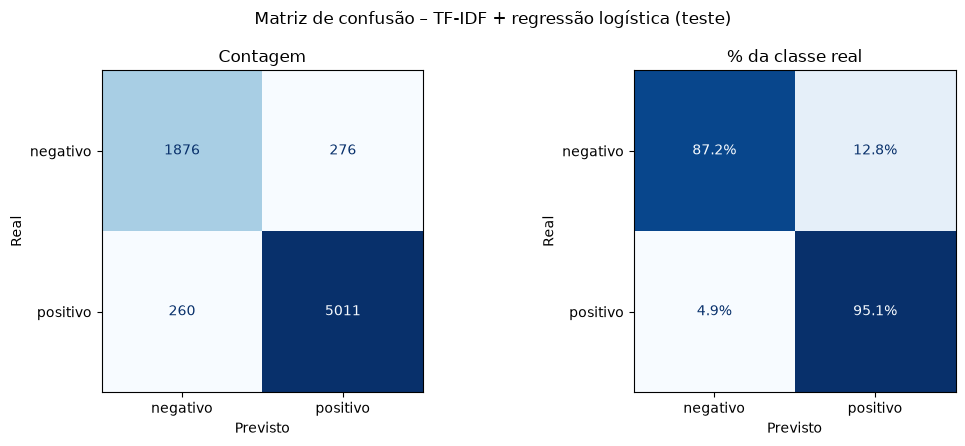

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
panels = [(None, "Contagem", "d"), ("true", "% da classe real", ".1%")]

for ax, (normalize, title, values_format) in zip(axes, panels, strict=True):
    ConfusionMatrixDisplay.from_predictions(
        split.test[SENTIMENT_COLUMN],
        model_predictions,
        labels=sentiment_labels,
        display_labels=sentiment_order,
        normalize=normalize,
        values_format=values_format,
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")

fig.suptitle("Matriz de confusão – TF-IDF + regressão logística (teste)")
fig.tight_layout()
plt.show()

### 3. Como ler a matriz

Cada **linha** é o que a avaliação era de verdade; cada **coluna**, o que o modelo disse. A diagonal são os acertos.

| | Previsto negativo | Previsto positivo |
|---|---|---|
| **Real negativo** | **1.876**: insatisfeitos encontrados | **276**: insatisfeitos que *escaparam* (o modelo disse "positivo" por engano) |
| **Real positivo** | **260**: *alarmes falsos* | **5.011**: satisfeitos reconhecidos |

- **Recall negativo** = 1.876 / (1.876 + 276) = **87,2%**: lido na linha de cima ("dos insatisfeitos, quantos achamos?").
- **Precisão negativa** = 1.876 / (1.876 + 260) = **87,8%**: lida na coluna da esquerda ("quando apontamos um insatisfeito, acertamos?").
- No baseline, a coluna "previsto negativo" inteira era zero.

### 4. Checagem de desconfiança

Um resultado bom demais (99%) costuma indicar erro, como vazamento de dados ou avaliação no próprio treino. Duas checagens:
- **Treino × teste**: se o treino for muito melhor que o teste, o modelo decorou em vez de aprender (overfitting).
- **Textos repetidos × inéditos** (achado do Passo 3): quanto da nota vem de frases que o modelo já tinha visto no treino.

In [30]:
def metrics_on(mask: pd.Series) -> dict[str, float]:
    """Métricas do modelo só nas avaliações do teste selecionadas pela máscara."""
    return asdict(
        evaluate_predictions(split.test.loc[mask, SENTIMENT_COLUMN], model_predictions[mask])
    )


train_metrics = evaluate_predictions(
    split.train[SENTIMENT_COLUMN], sentiment_model.predict(split.train[MESSAGE_COLUMN])
)

pd.DataFrame(
    {
        "treino": asdict(train_metrics),
        "teste": asdict(model_metrics),
        f"teste – repetidos ({repeated_in_test.sum():,})": metrics_on(repeated_in_test),
        f"teste – inéditos ({(~repeated_in_test).sum():,})": metrics_on(~repeated_in_test),
    }
).round(3)

,treino,teste,"teste – repetidos (1,181)","teste – inéditos (6,242)"
accuracy,0.944,0.928,0.979,0.918
negative_precision,0.904,0.878,0.972,0.873
negative_recall,0.903,0.872,0.824,0.875
negative_f1,0.903,0.875,0.892,0.874
macro_f1,0.932,0.912,0.940,0.907


### 5. Conclusões

| Métrica | Baseline | TF-IDF + regressão logística |
|---|---|---|
| Acurácia | 0,710 | **0,928** |
| F1 negativo | 0,000 | **0,875** |
| F1 macro | 0,415 | **0,912** |

- **O modelo supera o baseline com folga.** Acurácia de 92,8%, dentro dos 85–93% esperados. Das 2.152 avaliações negativas, encontra 1.876 (87,2%), e quando aponta uma negativa, acerta 87,8% das vezes.
- **O F1 negativo (0,875) fica abaixo do positivo (0,949):** a classe negativa tem menos exemplos para aprender, e os erros pesam mais nela.
- **Sem sinais de problema:**
  - treino (94,4%) e teste (92,8%) estão próximos, então o modelo generaliza em vez de decorar;
  - um resultado de 99% seria motivo para procurar vazamento.
- **Textos repetidos inflam um pouco a nota:**
  - nas 1.181 avaliações do teste com texto já visto no treino, a acurácia é 97,9%;
  - nas 6.242 inéditas, 91,8%.

  Os 91,8% são a estimativa mais honesta para avaliações novas. O F1 negativo quase não muda (0,874).
- **Os dois erros têm custos diferentes para o negócio:**
  - 276 clientes insatisfeitos passaram despercebidos;
  - 260 satisfeitos geraram alarme falso.

**Próximo passo:** analisar os erros, lendo as avaliações que o modelo errou para entender por quê.
